# Global template over $(w_0, w_a)$ backgrounds

Model `tanh_kB_L` (same shape as `tanh_kB`, with parameters that separate the roles of $c_B$ and of the background):
$$f(k) = L + A\left(\tanh\left[2\log_{10}(s\,k/k_B)\right] + 1\right)$$
- $L$: deviation at large scales ($k \ll k_B$). Depends only on the background.
- $2A$: height of the step. $s$: position of the transition ($k = k_B/s$). Depend on $c_B$.

Six coefficients, valid for every background:
$$A = m_A\,c_B + y_{0,A}, \qquad s = m_s\,c_B + y_{0,s} \qquad L = \ell_1 (1 + w_0) + \ell_2\, w_a$$

$A$ and $s$ come from weighted linear fits in $c_B$ with the spectra of all backgrounds at once; $L$ is
averaged over the spectra of each background and then fitted in $(w_0, w_a)$.

In [11]:
%reload_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import griddata

from hiclass_tools import load_spectra_group, fit_global_template, MODELS
from hiclass_tools.plotting import use_style, ColorScale

use_style(fontsize=12)

In [12]:
# Configuration
SPECTRA = 'range_DE_grid'
K_MIN = 3e-3                 # lower k limit of the fits and of the errors [h/Mpc] (None: whole range)

sets = load_spectra_group(SPECTRA)    # {(w0, wa): SpectraSet}
model = MODELS['tanh_kB_L']
cK = np.unique(np.concatenate([s.cK for s in sets.values()]))   # union over backgrounds
cB = np.unique(np.concatenate([s.cB for s in sets.values()]))
k = next(iter(sets.values())).k

print(f"{len(sets)} backgrounds: w0 in [{min(w0 for w0, _ in sets):.3g}, {max(w0 for w0, _ in sets):.3g}], "
      f"wa in [{min(wa for _, wa in sets):.3g}, {max(wa for _, wa in sets):.3g}]")
print(f"cK: {len(cK)} values in [{cK[0]:.3g}, {cK[-1]:.3g}]")
print(f"cB: {len(cB)} values in [{cB[0]:.3g}, {cB[-1]:.3g}]")
print(f"k:  {len(k)} values in [{k[0]:.3g}, {k[-1]:.3g}] h/Mpc")
print(f"Failed in CLASS (unstable models): {sum(len(s.failed) for s in sets.values())}")

25 backgrounds: w0 in [-1, -0.8], wa in [-1, 0]
cK: 10 values in [1e+03, 1e+06]
cB: 10 values in [0.5, 1.5]
k:  50 values in [0.001, 10] h/Mpc
Failed in CLASS (unstable models): 40


In [13]:
gfit = fit_global_template(sets, k_min=K_MIN)
template = gfit.template

print("Global template coefficients:")
for name, coeffs in [('A', template.A), ('s', template.s), ('L', template.L)]:
    print(f"  {name}: " + ',  '.join(f"{q} = {v:.5f} ± {e:.5f}" for q, (v, e) in coeffs.items()))
print(f"  R^2 of L(w0, wa): {gfit.L_r2:.3f}")

keys = list(sets)
w0_arr = np.array([w0 for w0, _ in keys])
wa_arr = np.array([wa for _, wa in keys])

# Mean errors per background: individual spectrum fits and global template
spectrum_err = gfit.spectrum_errors()
template_err = gfit.template_errors(k_min=K_MIN)
spectrum_err_arr = np.array([spectrum_err[key] for key in keys]) * 100
template_err_arr = np.array([template_err[key] for key in keys]) * 100

print(f"\nSpectrum fits:   median {np.median(spectrum_err_arr):.2f} %, max {spectrum_err_arr.max():.2f} %")
print(f"Global template: median {np.median(template_err_arr):.2f} %, max {template_err_arr.max():.2f} %")

# Backgrounds where CLASS rejected some (cK, cB) models as unstable
unstable = np.array([key for key, s in sets.items() if s.failed]).reshape(-1, 2)

def mark_unstable(ax, label=True):
    ax.scatter(unstable[:,0], unstable[:,1], marker='x', s=80, c='r', linewidths=2, clip_on=False, zorder=5,
               label=r'Unstable models (fewer $c_B$)' if label else None)

Global template coefficients:
  A: m = 0.02463 ± 0.00020,  y0 = 0.00076 ± 0.00019
  s: m = -0.40172 ± 0.00748,  y0 = 1.36567 ± 0.00924
  L: l1 = 0.02830 ± 0.00477,  l2 = 0.01886 ± 0.00095
  R^2 of L(w0, wa): 0.913

Spectrum fits:   median 3.94 %, max 4.43 %
Global template: median 12.05 %, max 25.14 %


## Linear fits

Text(0.5, 1, 'Global template: $f(k) = L + A \\left(\\tanh\\left[2\\log_{10}(s\\,k/k_B)\\right] + 1\\right)$')

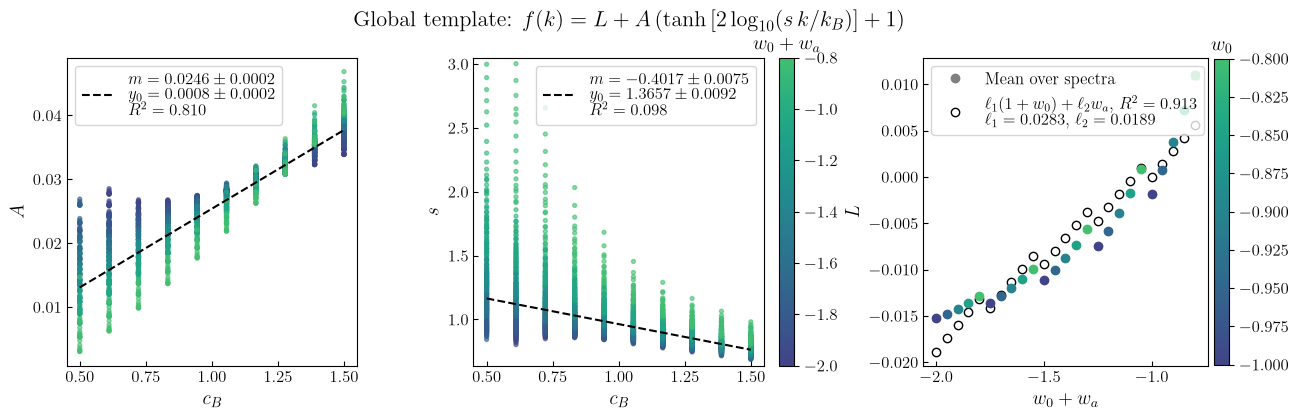

In [28]:
fits = [(key, f) for key, bg_fits in gfit.spectrum_fits.items() for f in bg_fits.values()]
cb_pts = np.array([f.cb for _, f in fits])
x_pts = np.array([key[0] + key[1] for key, _ in fits])          # w0 + wa of each spectrum
x_colors = ColorScale(x_pts, 'viridis')
w0_colors = ColorScale(w0_arr, 'viridis')
cb_line = np.linspace(cB[0], cB[-1], 50)

fig, axs = plt.subplots(1, 3, figsize=(15, 4))
fig.subplots_adjust(wspace=0.4)

# A and s vs cB: every spectrum of every background, coloured by w0 + wa
for ax, p, line, label in [(axs[0], 'A', gfit.A_fit, r'$A$'), (axs[1], 's', gfit.s_fit, r'$s$')]:
    values = np.array([f.params[p][0] for _, f in fits])
    ax.scatter(cb_pts, values, s=8, c=x_colors(x_pts), alpha=0.6)
    ax.plot(cb_line, line(cb_line), color='k', linestyle='--',
            label=(fr"$m={line.m:.4f} \pm {line.m_err:.4f}$" + '\n' + fr"$y_0={line.y0:.4f} \pm {line.y0_err:.4f}$"
                   + '\n' + fr"$R^2={line.r2:.3f}$"))
    ax.set_xlabel(r'$c_B$', fontsize=14)
    ax.set_ylabel(label, fontsize=14)
    ax.legend(loc='best')

# s has a few degenerate fits (s >> 1) with huge errors: show the bulk
s_values = np.array([f.params['s'][0] for _, f in fits])
axs[1].set_ylim(np.percentile(s_values, [0.5, 99]) * [0.9, 1.1])

cbar = plt.colorbar(x_colors.mappable, ax=axs[:2], fraction=0.03, pad=0.02)
cbar.ax.set_title(r'$w_0+w_a$')

# L per background vs w0 + wa: measured (filled) and model l1 (1 + w0) + l2 wa (open)
for (w0, wa), mean in gfit.L_means.items():
    axs[2].errorbar(w0 + wa, mean.value, yerr=mean.error, fmt='o', capsize=3, color=w0_colors(w0))
    axs[2].plot(w0 + wa, gfit.L_model(w0, wa), marker='o', markerfacecolor='none', color='k', linestyle='none')
axs[2].plot([], [], marker='o', color='gray', linestyle='none', label='Mean over spectra')
axs[2].plot([], [], marker='o', markerfacecolor='none', color='k', linestyle='none',
            label=(fr"$\ell_1 (1+w_0) + \ell_2 w_a$, $R^2={gfit.L_r2:.3f}$" + '\n' +
                   fr"$\ell_1={template.L['l1'][0]:.4f}$, $\ell_2={template.L['l2'][0]:.4f}$"))
axs[2].set_xlabel(r'$w_0 + w_a$', fontsize=14)
axs[2].set_ylabel(r'$L$', fontsize=14)
axs[2].legend(loc='upper left')
cbar = plt.colorbar(w0_colors.mappable, ax=axs[2], fraction=0.05, pad=0.02)
cbar.ax.set_title(r'$w_0$')

for ax in axs:
    ax.tick_params(axis='both', which='both', direction='in')
fig.suptitle(fr'Global template: $f(k) = {model.latex}$', fontsize=16, y=1)

## Errors: individual spectrum fits vs global template

Text(0.5, 1.01, 'Mean error per background ($k \\geq k_{\\rm min}$)')

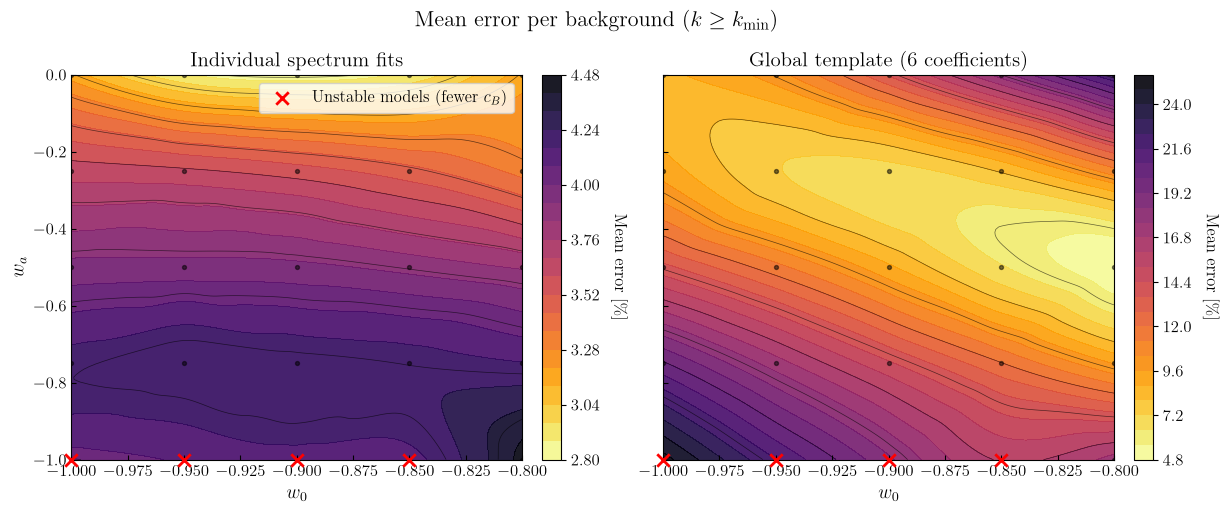

In [ ]:
W0, WA = np.meshgrid(np.linspace(w0_arr.min(), w0_arr.max(), 150), np.linspace(wa_arr.min(), wa_arr.max(), 150))

fig, axs = plt.subplots(1, 2, figsize=(14, 5), sharex=True, sharey=True)

for ax, values, title in [(axs[0], spectrum_err_arr, 'Individual spectrum fits'),
                          (axs[1], template_err_arr, 'Global template (6 coefficients)')]:
    Z = griddata((w0_arr, wa_arr), values, (W0, WA), method='cubic')
    contour = ax.contourf(W0, WA, Z, levels=25, cmap='inferno_r', alpha=0.9)
    ax.contour(W0, WA, Z, levels=12, colors='k', linewidths=0.5, alpha=0.6)
    ax.scatter(w0_arr, wa_arr, s=8, c='k', alpha=0.5)
    mark_unstable(ax, label=(ax is axs[0]))

    cbar = plt.colorbar(contour, ax=ax, fraction=0.046, pad=0.04)
    cbar.set_label(r'Mean error [\%]', rotation=270, labelpad=20, fontsize=12)

    ax.set_title(title, fontsize=15)
    ax.set_xlabel(r'$w_0$', fontsize=14)
    ax.tick_params(axis='both', which='both', direction='in')

axs[0].set_ylabel(r'$w_a$', fontsize=14)
axs[0].legend(loc='upper right')
fig.suptitle(r'Mean error per background ($k \geq k_{\rm min}$)', fontsize=16, y=1.01)

In [16]:
# Save the global template (data/templates/<name>.pkl). Load it later with GlobalTemplate.load(name)
template.save(f'{SPECTRA}_global')